Présentation des données et traitement

API Open Météo : 

In [1]:
from src.meteo import charger_meteo
from IPython.display import display #Pour afficher des beaux tableaux


#On appelle meteo_pur la data sans aucun traitement telle qu'on  l'a téléchargée de Open Meteo
meteo_pur= charger_meteo("data/raw/openmeteo") 

#Voila un aperçu des données
print(display(meteo_pur.head()), display(meteo_pur.describe()))
#Première remarque, on peut observer que la température moyenne est égale à environ 13 degrés donc froid selon notre convention. 
# C'est l'effet de la nuit sur la température moyenne (certains jours chaud d'été ont une température inférieur à 15°C la nuit mais ne sont pas froids pour autant).
#On prendra ce problème en compte dans notre traitement des données

#On observe bien que nos données couvre du premier janvier 2021 au 31 décembre 2025
print( "Les données couvrent de "+ str(meteo_pur["time"].min()) +" à " +str( meteo_pur["time"].max()))

#On observe bien que les 12 régions de la France métropolitaine (13 - la Corse) sont bien présentes (1 ville par région)
print("On observe bien au total "+str(meteo_pur["ville"].nunique() )+" régions")



,time,temperature_2m,shortwave_radiation,cloud_cover,wind_speed_10m,wind_speed_100m,precipitation,ville
0,2021-01-01 00:00:00+00:00,4.4,0.0,95,3.1,5.5,0.0,bordeaux
1,2021-01-01 01:00:00+00:00,3.3,0.0,96,3.4,3.5,0.0,bordeaux
2,2021-01-01 02:00:00+00:00,2.1,0.0,92,5.4,5.8,0.0,bordeaux
3,2021-01-01 03:00:00+00:00,1.9,0.0,92,5.9,12.0,0.0,bordeaux
4,2021-01-01 04:00:00+00:00,1.8,0.0,82,6.6,16.6,0.0,bordeaux


,temperature_2m,shortwave_radiation,cloud_cover,wind_speed_10m,wind_speed_100m,precipitation
count,525888.000000,525888.000000,525888.000000,525888.000000,525888.000000,525888.000000
mean,12.986467,151.895489,61.493029,12.207613,20.616850,0.099247
std,7.283659,227.364982,41.271378,6.945876,10.762091,0.457567
min,-11.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,7.900000,0.000000,15.000000,7.100000,12.800000,0.000000
50%,12.700000,7.000000,83.000000,10.900000,19.700000,0.000000
75%,18.000000,249.000000,100.000000,16.000000,26.800000,0.000000
max,41.700000,958.000000,100.000000,69.900000,102.400000,24.400000


None None
Les données couvrent de 2021-01-01 00:00:00+00:00 à 2025-12-31 23:00:00+00:00
On observe bien au total 12 régions


In [2]:
from src.meteo import preparer_meteo
#Les données sont globalement déjà propres
print("pour chaque variable, on vérifie bien qu'on a toutes les observations", meteo_pur.isna().sum(), "puis combien de doublon il y a",meteo_pur.duplicated(["ville", "time"]).sum())
#Les noms de colonnes sont également assez explicites donc on a pas vraiment trouvé d'intérêt à les renommer.

meteo = preparer_meteo(meteo_pur) 
meteo.head()

pour chaque variable, on vérifie bien qu'on a toutes les observations time                   0
temperature_2m         0
shortwave_radiation    0
cloud_cover            0
wind_speed_10m         0
wind_speed_100m        0
precipitation          0
ville                  0
dtype: int64 puis combien de doublon il y a 0


,time,temperature_2m,shortwave_radiation,cloud_cover,wind_speed_10m,wind_speed_100m,precipitation,ville,jour,sous_15,sup_27,deg_sous_15,deg_sup_27,tmax_jour,tmoy_jour,jour_chaud,jour_froid,vent100_moy_jour,vent100_max_jour
0,2021-01-01 01:00:00+01:00,4.4,0.0,95,3.1,5.5,0.0,bordeaux,2021-01-01,True,False,10.6,0.0,6.1,3.752174,False,True,18.308696,28.0
1,2021-01-01 02:00:00+01:00,3.3,0.0,96,3.4,3.5,0.0,bordeaux,2021-01-01,True,False,11.7,0.0,6.1,3.752174,False,True,18.308696,28.0
2,2021-01-01 03:00:00+01:00,2.1,0.0,92,5.4,5.8,0.0,bordeaux,2021-01-01,True,False,12.9,0.0,6.1,3.752174,False,True,18.308696,28.0
3,2021-01-01 04:00:00+01:00,1.9,0.0,92,5.9,12.0,0.0,bordeaux,2021-01-01,True,False,13.1,0.0,6.1,3.752174,False,True,18.308696,28.0
4,2021-01-01 05:00:00+01:00,1.8,0.0,82,6.6,16.6,0.0,bordeaux,2021-01-01,True,False,13.2,0.0,6.1,3.752174,False,True,18.308696,28.0


Rapide exploration des données d'Open Meteo

Nous allons effectuer quelques graphiques utiles pour explorer nos données et plus tard pour considérer nos hypothèses.

Tout d'abords pour vérifier la corrélation entre production d'énérgie hydraulique et précipatation, il sera utile d'avoir un graphe des précipitations. On regroupe les données par mois et on affiche le graphique pour Bordeaux.

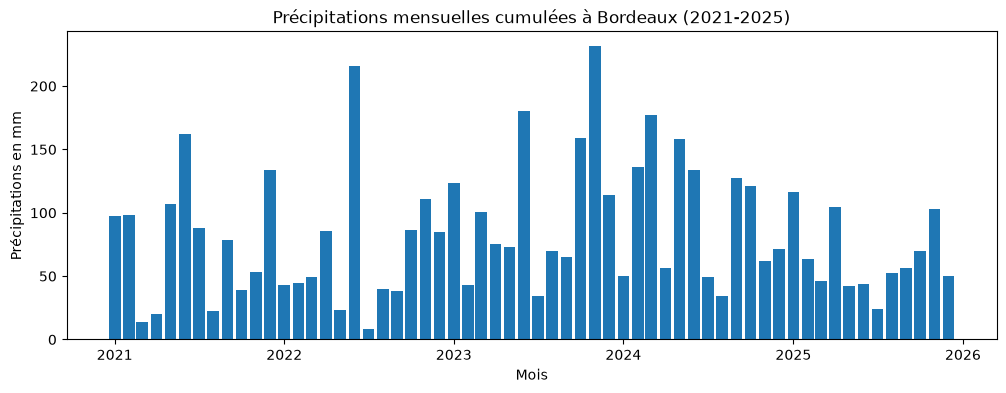

In [3]:
import matplotlib.pyplot as plt
import src.meteo
from src.meteo import cumul_mensuel


ville = "bordeaux"
pluie = cumul_mensuel(meteo, ville)

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(pluie.index, pluie.values, width=25)
ax.set_title(f"Précipitations mensuelles cumulées à {ville.capitalize()} (2021-2025)")
ax.set_xlabel("Mois")
ax.set_ylabel("Précipitations en mm")
plt.show()

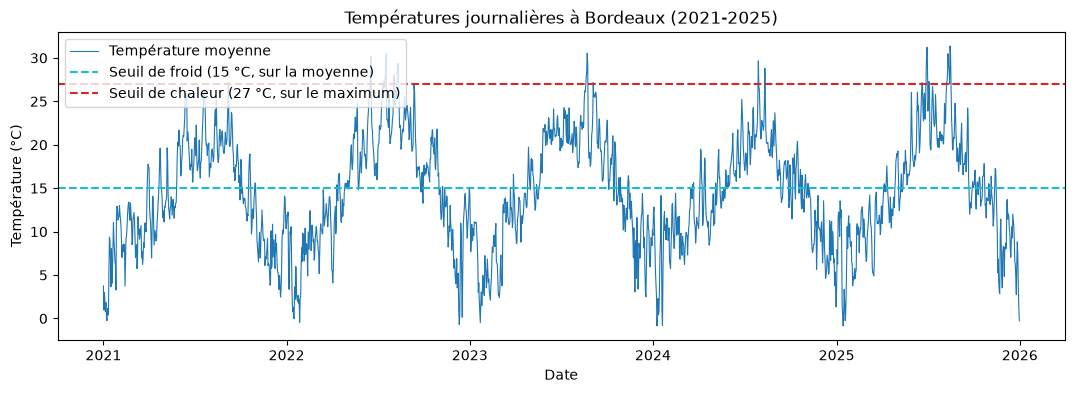

In [4]:
import matplotlib.pyplot as plt
from src.meteo import temperature_moyenne_jour, SEUIL_FROID, SEUIL_CHAUD

ville = "bordeaux"
tmoy = temperature_moyenne_jour(meteo, ville)


fig, ax = plt.subplots(figsize=(13, 4))

ax.plot(tmoy.index, tmoy.values, linewidth=0.8, color="tab:blue", label="Température moyenne")
ax.axhline(SEUIL_FROID, color="tab:cyan", linestyle="--", label=f"Seuil de froid ({SEUIL_FROID} °C, sur la moyenne)")
ax.axhline(SEUIL_CHAUD, color="tab:red", linestyle="--", label=f"Seuil de chaleur ({SEUIL_CHAUD} °C, sur le maximum)")
ax.set_title(f"Températures journalières à {ville.capitalize()} (2021-2025)")
ax.set_xlabel("Date"); ax.set_ylabel("Température (°C)")
ax.legend(loc="upper left")
plt.show()

#On observe que très peu de jours sont au dessus du seuil de chaleur (27 degré). C'est "l'effet nuit qu'on a déjà mentionné.
#On génère donc en ne prenant que les données entre 8h et 20h (C'est un choix assez arbitraire car le jour et la nuit commence différement selon les saisons mais c'est le choix que l'on a fait ici.)

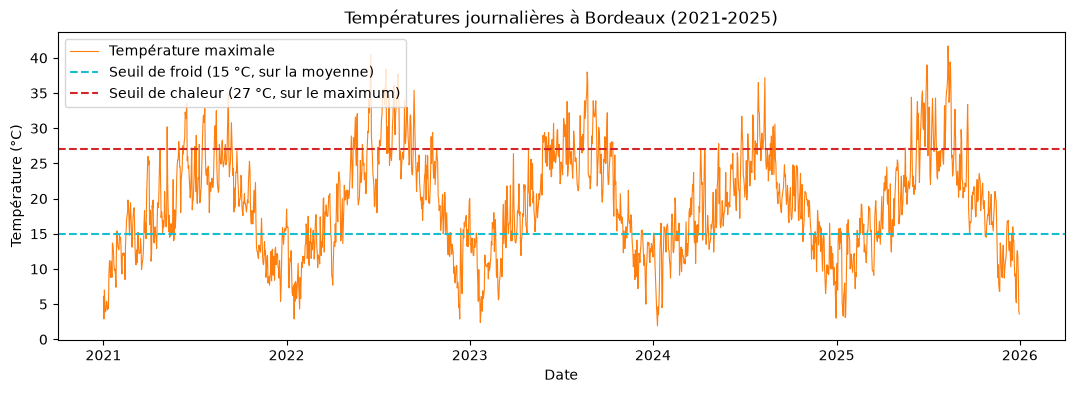

In [5]:
from src.meteo import temperature_max_jour, SEUIL_FROID, SEUIL_CHAUD

ville = "bordeaux"
tmax = temperature_max_jour(meteo, ville)

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(tmax.index, tmax.values, linewidth=0.8, color="tab:orange", label="Température maximale")
ax.axhline(SEUIL_FROID, color="tab:cyan", linestyle="--", label=f"Seuil de froid ({SEUIL_FROID} °C, sur la moyenne)")
ax.axhline(SEUIL_CHAUD, color="tab:red", linestyle="--", label=f"Seuil de chaleur ({SEUIL_CHAUD} °C, sur le maximum)")
ax.set_title(f"Températures journalières à {ville.capitalize()} (2021-2025)")
ax.set_xlabel("Date"); ax.set_ylabel("Température (°C)")
ax.legend(loc="upper left")
plt.show()

In [6]:
# Un seul enregistrement par ville et par jour
jours = meteo.drop_duplicates(["ville", "jour"])

# Nombre de jours froids par ville (2021-2025)
jours_froids = jours.groupby("ville")["jour_froid"].sum().sort_values(ascending=False)
print("Jours froids par ville :")
print(jours_froids)

# Nombre de jours chauds par ville (2021-2025)
jours_chauds = jours.groupby("ville")["jour_chaud"].sum().sort_values(ascending=False)
print("\nJours chauds par ville :")
print(jours_chauds)

Jours froids par ville :
ville
rouen         1233
lille         1220
dijon         1192
rennes        1168
paris         1156
orleans       1152
strasbourg    1145
nantes        1090
lyon          1084
bordeaux       994
toulouse       986
marseille      857
Name: jour_froid, dtype: int64

Jours chauds par ville :
ville
toulouse      349
marseille     310
lyon          293
bordeaux      265
strasbourg    198
dijon         171
paris         161
orleans       158
nantes        147
rennes        122
rouen          85
lille          82
Name: jour_chaud, dtype: int64


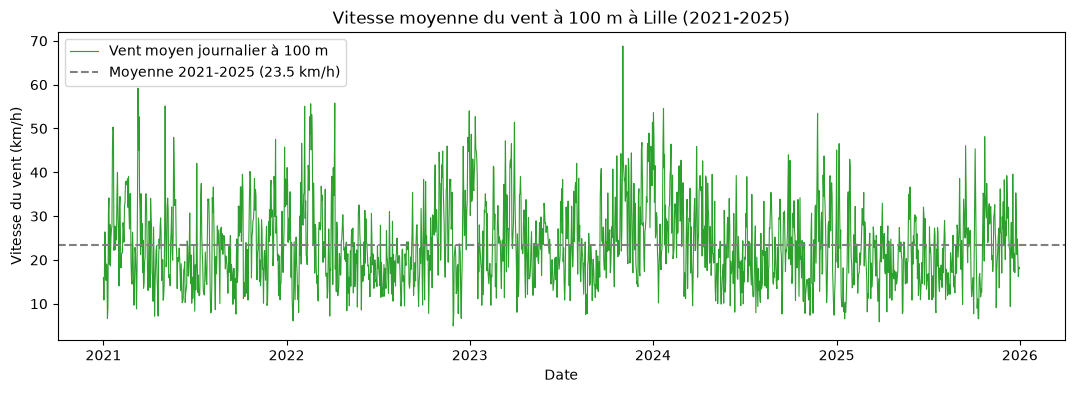

In [7]:
#Et enfin même travail pour la vitesse du vent à 100m (les éoliennes font plus de 100m)
import matplotlib.pyplot as plt
from src.meteo import vent_moyen_jour

ville = "lille"
vent = vent_moyen_jour(meteo, ville)

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(vent.index, vent.values, linewidth=0.8, color="tab:green", label="Vent moyen journalier à 100 m")
ax.axhline(vent.mean(), color="gray", linestyle="--", label=f"Moyenne 2021-2025 ({vent.mean():.1f} km/h)")
ax.set_title(f"Vitesse moyenne du vent à 100 m à {ville.capitalize()} (2021-2025)")
ax.set_xlabel("Date"); ax.set_ylabel("Vitesse du vent (km/h)")
ax.legend(loc="upper left")
plt.show()

Traitement des données d'Open Météo

API : ECO2Mix

In [8]:
import pandas as pd

#On appelle elec_pur les données éCO2mix telles qu'on les a téléchargées depuis l'API ODRÉ
from src.electricite import charger_eco2mix

elec_pur = charger_eco2mix()

#Aperçu des données
display(elec_pur.head())

#Vérification de la période couverte et du nombre de régions
print("Les données couvrent de " + str(elec_pur["date_heure"].min()) + " à " + str(elec_pur["date_heure"].max()))
print("On observe au total " + str(elec_pur["code_insee_region"].nunique()) + " régions")


,code_insee_region,libelle_region,date_heure,consommation,nucleaire,eolien,solaire,hydraulique
0,44,Grand Est,2025-12-31T23:30:00+00:00,5870.0,8963.0,45,0.0,524.0
1,11,Île-de-France,2025-12-31T23:30:00+00:00,10410.0,0.0,0,0.0,5.0
2,52,Pays de la Loire,2025-12-31T23:30:00+00:00,4569.0,0.0,934,0.0,3.0
3,24,Centre-Val de Loire,2025-12-31T23:30:00+00:00,3139.0,10323.0,148,0.0,3.0
4,76,Occitanie,2025-12-31T23:30:00+00:00,6387.0,1247.0,55,0.0,1377.0


Les données couvrent de 2021-01-01T00:00:00+00:00 à 2025-12-31T23:30:00+00:00
On observe au total 12 régions


In [9]:
from src.electricite import preparer_eco2mix

#On passe de la demi-heure à l'heure (moyenne des deux demi-heures, car ce sont des puissances en MW)
#et on associe à chaque région son chef-lieu, pour pouvoir fusionner avec la météo
elec_horaire = preparer_eco2mix(elec_pur)

display(elec_horaire.head())
print("Nombre de lignes : " + str(len(elec_horaire)))


,code_insee_region,time,consommation,nucleaire,eolien,solaire,hydraulique,ville
0,11,2021-01-01 00:00:00+00:00,9495.0,0.0,1.0,0.0,3.0,paris
1,11,2021-01-01 01:00:00+00:00,9061.0,0.0,1.5,0.0,3.0,paris
2,11,2021-01-01 02:00:00+00:00,8690.0,0.0,0.0,0.0,3.0,paris
3,11,2021-01-01 03:00:00+00:00,8429.0,0.0,0.0,0.0,3.0,paris
4,11,2021-01-01 04:00:00+00:00,8446.5,0.0,0.5,0.0,3.0,paris


Nombre de lignes : 525828


Après passage à l'heure, on obtient 525 828 lignes au lieu des 525 888 attendues (12 villes × 1 826 jours × 24 heures). Il manque une heure par an et par région : celle du passage à l'heure d'hiver en octobre (00h-01h UTC), absente des données RTE. Ces 60 heures, soit 0,01 % des données, seront écartées lors de la jointure avec la météo.


Jointure entre les deux bases de données

In [10]:
#On fusionne l'électricité (elec_horaire) et la météo préparée (meteo) sur la ville et l'heure.
#Les deux colonnes time ont des fuseaux différents (UTC et Paris) mais pandas les compare comme des instants.
donnees = pd.merge(elec_horaire, meteo, on=["ville", "time"], how="inner")

#Après la fusion, time est en UTC (fuseau du tableau de gauche) : on le remet en heure française pour les analyses par heure
donnees["time"] = donnees["time"].dt.tz_convert("Europe/Paris")

display(donnees.head())
print("Nombre de lignes après jointure : " + str(len(donnees)))
print("Valeurs manquantes : " + str(donnees.isna().sum().sum()))


,code_insee_region,time,consommation,nucleaire,eolien,solaire,hydraulique,ville,temperature_2m,shortwave_radiation,...,sous_15,sup_27,deg_sous_15,deg_sup_27,tmax_jour,tmoy_jour,jour_chaud,jour_froid,vent100_moy_jour,vent100_max_jour
0,11,2021-01-01 01:00:00+01:00,9495.0,0.0,1.0,0.0,3.0,paris,-0.6,0.0,...,True,False,15.6,0.0,3.6,0.291304,False,True,8.995652,12.7
1,11,2021-01-01 02:00:00+01:00,9061.0,0.0,1.5,0.0,3.0,paris,-1.6,0.0,...,True,False,16.6,0.0,3.6,0.291304,False,True,8.995652,12.7
2,11,2021-01-01 03:00:00+01:00,8690.0,0.0,0.0,0.0,3.0,paris,-2.0,0.0,...,True,False,17.0,0.0,3.6,0.291304,False,True,8.995652,12.7
3,11,2021-01-01 04:00:00+01:00,8429.0,0.0,0.0,0.0,3.0,paris,-1.8,0.0,...,True,False,16.8,0.0,3.6,0.291304,False,True,8.995652,12.7
4,11,2021-01-01 05:00:00+01:00,8446.5,0.0,0.5,0.0,3.0,paris,-1.9,0.0,...,True,False,16.9,0.0,3.6,0.291304,False,True,8.995652,12.7


Nombre de lignes après jointure : 525816
Valeurs manquantes : 0


La jointure donne 525 816 lignes. On perd les 60 heures absentes d'éCO2mix au passage à l'heure d'hiver, ainsi que la dernière heure du 31/12/2025, qui tombe en 2026 en heure française. Il n'y a aucune valeur manquante : les deux bases sont prêtes pour l'analyse.


Analyses de nos hypothèses

Conclusions